In [7]:
import pandas as pd
import tensorflow as tf
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

In [12]:
train_data = pd.read_csv("fashion_mnist_train.csv")
test_data = pd.read_csv("fashion_mnist_test.csv")
x_train = train_data.drop("label",axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label",axis=1).values
y_test = test_data["label"].values

print("Training data size:",x_train.shape)
print("Testing data size:",x_test.shape)

Training data size: (60000, 784)
Testing data size: (10000, 784)


In [20]:
model = keras.Sequential([
    layers.Flatten(input_shape=(784,)),
    layers.Dense(128,activation="relu"),
    layers.Dense(64,activation="relu"),
    layers.Dense(10,activation="softmax")
])

In [21]:
model.compile(
    optimizer = keras.optimizers.SGD(learning_rate=0.01),
    loss = 'sparse_categorical_crossentropy',
    metrics=["accuracy"]
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size = 32,    
    validation_split=0.1,
    verbose=1
)

Epoch 1/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7497 - loss: 0.7520 - val_accuracy: 0.8097 - val_loss: 0.5397
Epoch 2/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8242 - loss: 0.5072 - val_accuracy: 0.8317 - val_loss: 0.4684
Epoch 3/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8403 - loss: 0.4604 - val_accuracy: 0.8382 - val_loss: 0.4517
Epoch 4/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8490 - loss: 0.4320 - val_accuracy: 0.8447 - val_loss: 0.4380
Epoch 5/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8576 - loss: 0.4110 - val_accuracy: 0.8538 - val_loss: 0.4152
Epoch 6/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8611 - loss: 0.3957 - val_accuracy: 0.8610 - val_loss: 0.3911
Epoch 7/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8661 - loss: 0.3801 - val_accuracy: 0.8615 - val_loss: 0.3882
Epoch 8/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8708 - loss: 0.3691 - 

In [23]:
test_loss,test_accuracy = model.evaluate(x_test,y_test)
print("Test loss:",test_loss)
print("Test accuracy:",test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8596 - loss: 0.3988  
Test loss: 0.39880189299583435
Test accuracy: 0.8596000075340271


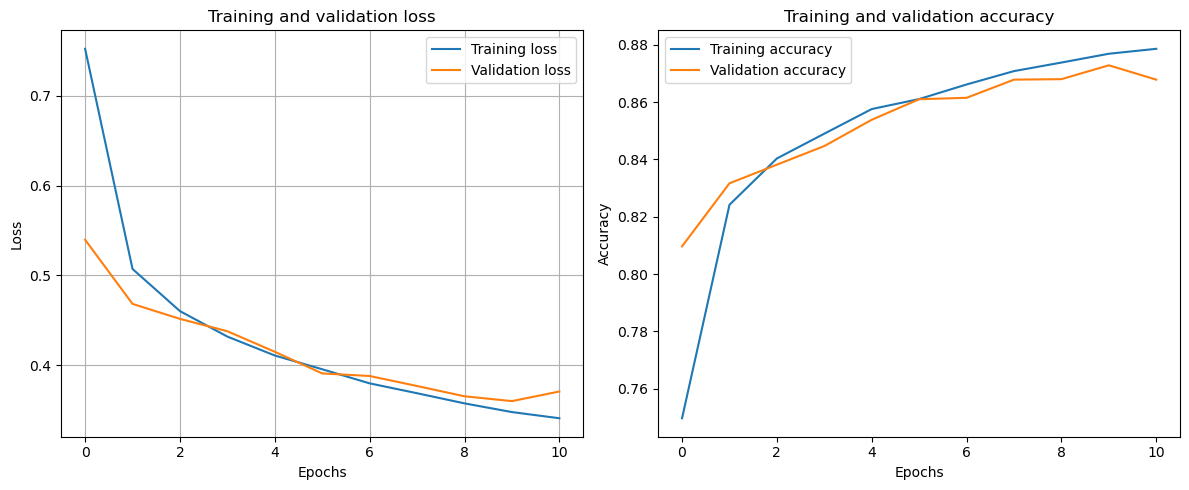

In [26]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)   

plt.subplot(1,2,2)
plt.plot(history.history["accuracy"],label="Training accuracy")
plt.plot(history.history["val_accuracy"],label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import tensorflow as tf
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

train_data = pd.read_csv("fashion_mnist_train.csv")
test_data = pd.read_csv("fashion_mnist_test.csv")
x_train = train_data.drop("label",axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label",axis=1).values
y_test = test_data["label"].values

print("Training data size:",x_train.shape)
print("Testing data size:",x_test.shape)

x_train = x_train/255.0
x_test = x_test/255.0

model = keras.Sequential([
    layers.Flatten(input_shape=(784,)),
    layers.Dense(128,activation="relu"),
    layers.Dense(64,activation="relu"),
    layers.Dense(10,activation="softmax")
])

model.compile(
    optimizer = keras.optimizers.SGD(learning_rate=0.01),
    loss = 'sparse_categorical_crossentropy',
    metrics=["accuracy"]
)
model.summary()

history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size = 32,    
    validation_split=0.1,
    verbose=1
)

test_loss,test_accuracy = model.evaluate(x_test,y_test)
print("Test loss:",test_loss)
print("Test accuracy:",test_accuracy)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)   

plt.subplot(1,2,2)
plt.plot(history.history["accuracy"],label="Training accuracy")
plt.plot(history.history["val_accuracy"],label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()
